In [4]:
# Import necessary libraries

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score , confusion_matrix, classification_report , recall_score , precision_score, f1_score
import os
import joblib




In [5]:
# Load the dataset
df = pd.read_csv('dataset.csv')

df = pd.DataFrame(df)

print("Dataset shape:", df.shape)
print("First few rows of the dataset:")
print(df.head())

Dataset shape: (43400, 12)
First few rows of the dataset:
      id  gender   age  ...   bmi   smoking_status stroke
0  30669    Male   3.0  ...  18.0              NaN      0
1  30468    Male  58.0  ...  39.2     never smoked      0
2  16523  Female   8.0  ...  17.6              NaN      0
3  56543  Female  70.0  ...  35.9  formerly smoked      0
4  46136    Male  14.0  ...  19.1              NaN      0

[5 rows x 12 columns]


In [6]:
# data information
print("Dataset information:")
print(df.info())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43400 entries, 0 to 43399
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 43400 non-null  int64  
 1   gender             43400 non-null  object 
 2   age                43400 non-null  float64
 3   hypertension       43400 non-null  int64  
 4   heart_disease      43400 non-null  int64  
 5   ever_married       43400 non-null  object 
 6   work_type          43400 non-null  object 
 7   Residence_type     43400 non-null  object 
 8   avg_glucose_level  43400 non-null  float64
 9   bmi                41938 non-null  float64
 10  smoking_status     30108 non-null  object 
 11  stroke             43400 non-null  int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 4.0+ MB
None


In [7]:
#check duplicated rows

print(df.duplicated().sum())

# remove id column
df.drop('id', axis=1, inplace=True)

0


<Axes: title={'center': 'Stroke Class Distribution'}, xlabel='stroke'>

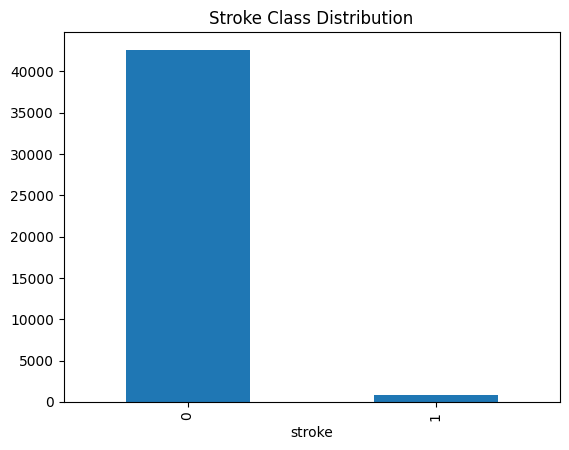

In [8]:
#check imbalance dataset

df['stroke'].value_counts().plot(kind='bar', title='Stroke Class Distribution')


In [9]:
# check missing values in each column
missing_values = df.isnull().sum()
print("Missing values in each column:")
print(missing_values)


Missing values in each column:
gender                   0
age                      0
hypertension             0
heart_disease            0
ever_married             0
work_type                0
Residence_type           0
avg_glucose_level        0
bmi                   1462
smoking_status       13292
stroke                   0
dtype: int64


In [10]:
# handle missing values

df['bmi'] = df['bmi'].fillna(df['bmi'].mean())
df['smoking_status'] = df['smoking_status'].fillna('Unknown')


In [11]:
# display dataset after handling missing values
print("Dataset after handling missing values:")
df.isnull().sum()

Dataset after handling missing values:


gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

In [12]:
categorical_columns = [
    'gender',
    'ever_married',
    'work_type',
    'Residence_type',
    'smoking_status'
]

# Apply label encoding to categorical columns

label_encoders = {}
for col in categorical_columns:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le

In [13]:
# separate features and target variable
X = df.drop('stroke', axis=1)
y = df['stroke']


In [14]:
# split dataset

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


<Axes: title={'center': 'Stroke Class Distribution After SMOTE'}, xlabel='stroke'>

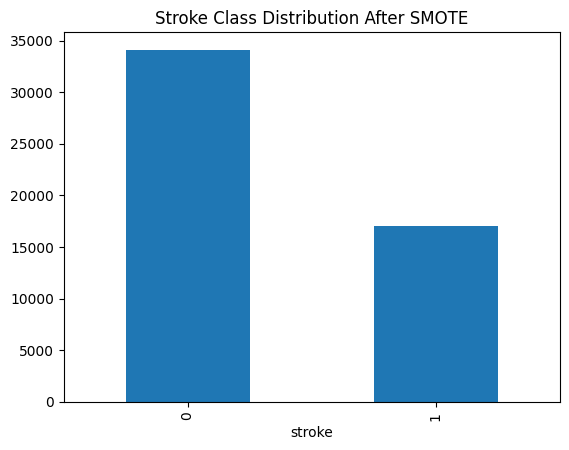

In [15]:
# apply SMOTE to handle class imbalance

smote = SMOTE(random_state=42 , sampling_strategy=0.5)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

y_train_smote.value_counts().plot(kind='bar', title='Stroke Class Distribution After SMOTE')


In [16]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
x_test = scaler.transform(X_test)

In [17]:
# apply logistic regression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_smote, y_train_smote)

y_pred_logistic = logistic_model.predict(X_test)



In [18]:
# evaluate logistic regression model
accuracy_logistic = accuracy_score(y_test, y_pred_logistic)
confusion_logistic = confusion_matrix(y_test, y_pred_logistic)
recall_score_logistic = recall_score(y_test, y_pred_logistic)
precision_score_logistic = precision_score(y_test, y_pred_logistic)
f1_score_logistic = f1_score(y_test, y_pred_logistic)

print("Logistic Regression Model Evaluation:")
print(f'Accuracy: {accuracy_logistic:.2f}')
print(f'Confusion Matrix:\n{confusion_logistic}')
print(f'Recall: {recall_score_logistic:.2f}')
print(f'Precision: {precision_score_logistic:.2f}')
print(f'F1-Score: {f1_score_logistic:.2f}')
print(classification_report(y_test, y_pred_logistic))

Logistic Regression Model Evaluation:
Accuracy: 0.86
Confusion Matrix:
[[7421 1098]
 [  98   63]]
Recall: 0.39
Precision: 0.05
F1-Score: 0.10
              precision    recall  f1-score   support

           0       0.99      0.87      0.93      8519
           1       0.05      0.39      0.10       161

    accuracy                           0.86      8680
   macro avg       0.52      0.63      0.51      8680
weighted avg       0.97      0.86      0.91      8680



In [19]:
# calculation logistic regression result

logistic_metric = {
    'Accuracy' : accuracy_score(
        y_test,
        y_pred_logistic
    ),

    'Precision': precision_score(
        y_test,
        y_pred_logistic,
        zero_division=0
    ),

    'Recall': recall_score(
        y_test,
        y_pred_logistic,
        zero_division=0
    ),

    'F1_score': f1_score(
        y_test,
        y_pred_logistic,
        zero_division=0
    )
}

logistic_confusion_matrix = confusion_matrix(
    y_test,
    y_pred_logistic
)

logistic_report = classification_report(
    y_test,
    y_pred_logistic,
    target_names=['No Stroke' , 'Stroke'],
    output_dict=True,
    zero_division=0
)

# create a models folder 
os.makedirs('models' , exist_ok=True)

model_bundle = {
    'model': logistic_model,
    'scaler': scaler,
    'label_encoders': label_encoders,
    'feature_columns': list(X.columns),
    'confusion_matrix': logistic_confusion_matrix,
    'classification_report' : logistic_report
}

joblib.dump(
    model_bundle,
    "models/logistic_stroke_model.joblib"
)




['models/logistic_stroke_model.joblib']

In [20]:
# apply SVM

svm_model = SVC(
    max_iter=100,
    random_state=42
)

svm_model.fit(X_train_smote, y_train_smote)

y_pred_svm = svm_model.predict(X_test)


c:\Users\MSI\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


In [21]:
# evaluate svm model

accuracy_svm = accuracy_score(y_test, y_pred_svm)
confusion_svm = confusion_matrix(y_test, y_pred_svm)
recall_score_svm = recall_score(y_test, y_pred_svm)
precision_score_svm = precision_score(y_test, y_pred_svm)
f1_score_svm = f1_score(y_test, y_pred_svm)

print("SVM Model Evaluation:")
print(f'Accuracy: {accuracy_svm:.2f}')
print(f'Confusion Matrix:\n{confusion_svm}')
print(f'Recall: {recall_score_svm:.2f}')
print(f'Precision: {precision_score_svm:.2f}')
print(f'F1-Score: {f1_score_svm:.2f}')
print(classification_report(y_test, y_pred_svm))

SVM Model Evaluation:
Accuracy: 0.80
Confusion Matrix:
[[6863 1656]
 [ 103   58]]
Recall: 0.36
Precision: 0.03
F1-Score: 0.06
              precision    recall  f1-score   support

           0       0.99      0.81      0.89      8519
           1       0.03      0.36      0.06       161

    accuracy                           0.80      8680
   macro avg       0.51      0.58      0.47      8680
weighted avg       0.97      0.80      0.87      8680



In [22]:
# xgboost model

xgb_model = XGBClassifier(
    random_state=42
)

xgb_model.fit(X_train_smote, y_train_smote)
y_pred_xgb = xgb_model.predict(X_test)

In [23]:
# evaluate xgboost model

accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
confusion_xgb = confusion_matrix(y_test, y_pred_xgb)
recall_score_xgb = recall_score(y_test, y_pred_xgb)
precision_score_xgb = precision_score(y_test, y_pred_xgb)
f1_score_xgb = f1_score(y_test, y_pred_xgb)

print("XGBoost Model Evaluation:")
print(f'Accuracy: {accuracy_xgb:.2f}')
print(f'Confusion Matrix:\n{confusion_xgb}')
print(f'Recall: {recall_score_xgb:.2f}')
print(f'Precision: {precision_score_xgb:.2f}')
print(f'F1-Score: {f1_score_xgb:.2f}')
print(classification_report(y_test, y_pred_xgb))


XGBoost Model Evaluation:
Accuracy: 0.97
Confusion Matrix:
[[8381  138]
 [ 150   11]]
Recall: 0.07
Precision: 0.07
F1-Score: 0.07
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      8519
           1       0.07      0.07      0.07       161

    accuracy                           0.97      8680
   macro avg       0.53      0.53      0.53      8680
weighted avg       0.97      0.97      0.97      8680



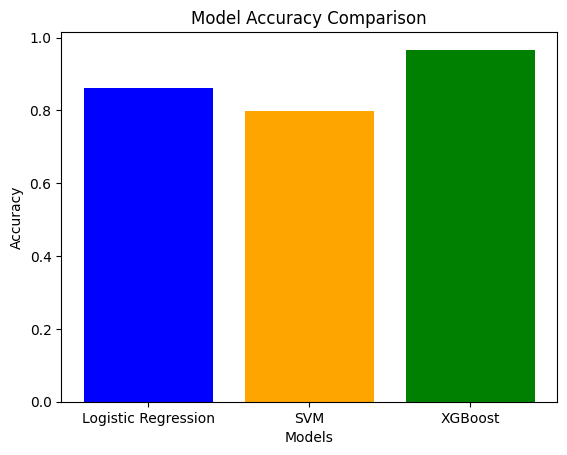

In [24]:
# compare model performance

models = ['Logistic Regression', 'SVM', 'XGBoost']
accuracies = [accuracy_logistic, accuracy_svm, accuracy_xgb]

plt.bar(models, accuracies , color=['blue', 'orange', 'green'])
plt.title('Model Accuracy Comparison') 
plt.xlabel('Models')
plt.ylabel('Accuracy')
plt.show()
